<a href="https://colab.research.google.com/github/julienessan/Gomycode_Cours_Data_Sciences/blob/main/Checkpoint_Entra%C3%AEner_un_r%C3%A9seau_de_neurones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint: Entraîner un réseau de neurones avec explication

**Objectif** :

Appliquer les concepts clés de la propagation avant (forward propagation) et de la rétropropagation (backward propagation) en entraînant un réseau de neurones simple et en expliquant comment il apprend à partir des données.

**Jeu de données** : Iris, 150 fleurs décrites par 4 mesures, réparties en 3 espèces.

**Architecture**
- Couche d'entrée : 4 caractéristiques
- Couche cachée : 8 neurones, activation `ReLU`
- Couche de sortie : 3 neurones, activation `softmax` (une probabilité par espèce)


## Étape 0 : imports bibliotèque


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## Étape 1 : chargement du jeu de données iris


In [2]:
iris = load_iris()
X, y = iris.data, iris.target
noms_classes = iris.target_names

df = pd.DataFrame(X, columns=iris.feature_names)
df["espece"] = [noms_classes[i] for i in y]
print("X :", X.shape, "| y :", y.shape)
print(df["espece"].value_counts(), "\n")
df.head()

X : (150, 4) | y : (150,)
espece
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64 



,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),espece
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Étape 2 : séparer train / test et normaliser


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (120, 4) | Test : (30, 4)


## Étape 3 : créeation du réseau

- `Dense` = couche entièrement connectée : chaque neurone reçoit toutes les sorties de la couche précédente.
- `ReLU` renvoie `max(0, z)`. Elle introduit la non-linéarité et se calcule très vite.
- `softmax` transforme les 3 scores de sortie en 3 probabilités dont la somme vaut 1.

Nombre de paramètres : couche cachée 4×8 + 8 = 40, sortie 8×3 + 3 = 27, soit 67 au total.

In [4]:
model = keras.Sequential([
    keras.Input(shape=(4,)),
    keras.layers.Dense(8, activation="relu", name="cachee"),
    keras.layers.Dense(3, activation="softmax", name="sortie"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cachee (Dense)                  │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sortie (Dense)                  │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

## Étape 4 : compilation du modèle

- **Perte** : `sparse_categorical_crossentropy`, l'entropie croisée pour plusieurs classes. Le préfixe *sparse* veut dire que les étiquettes restent des entiers (0, 1, 2) au lieu d'être encodées en one-hot.
- **Optimiseur** : `Adam`, une descente de gradient qui adapte le pas d'apprentissage de chaque poids.
- **Métrique** : la précision (accuracy), uniquement pour l'affichage. Elle n'intervient pas dans l'apprentissage.

In [5]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

## Étape 5 : entraîner le modèle


In [7]:
historique = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    verbose=0,
)

for e in [0] + list(range(4, 50, 5)):
    perte = historique.history["loss"][e]
    acc = historique.history["accuracy"][e]
    print(f"Époque {e + 1:>3} | perte = {perte:.4f} | précision = {acc:.2%}")

Époque   1 | perte = 0.7936 | précision = 70.00%
Époque   5 | perte = 0.3927 | précision = 82.50%
Époque  10 | perte = 0.2753 | précision = 89.17%
Époque  15 | perte = 0.1541 | précision = 93.33%
Époque  20 | perte = 0.0846 | précision = 96.67%
Époque  25 | perte = 0.0670 | précision = 97.50%
Époque  30 | perte = 0.0586 | précision = 97.50%
Époque  35 | perte = 0.0535 | précision = 97.50%
Époque  40 | perte = 0.0498 | précision = 97.50%
Époque  45 | perte = 0.0470 | précision = 98.33%
Époque  50 | perte = 0.0448 | précision = 98.33%


## Étape 6 : courbe de la perte

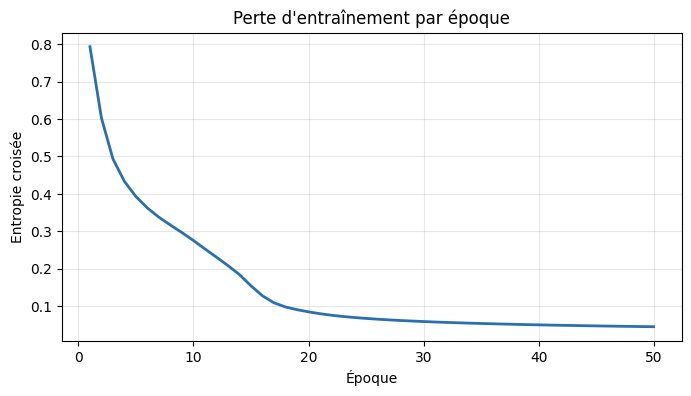

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, 51), historique.history["loss"], color="#2a6fb0", linewidth=2)
plt.title("Perte d'entraînement par époque")
plt.xlabel("Époque")
plt.ylabel("Entropie croisée")
plt.grid(alpha=0.3)
plt.show()

## Étape 7 : évaluer sur le jeu de test


In [9]:
perte_test, acc_test = model.evaluate(X_test, y_test, verbose=0)
print(f"Perte test : {perte_test:.4f} | précision test : {acc_test:.2%}\n")

y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
cm = pd.DataFrame(confusion_matrix(y_test, y_pred),
                  index=[f"vrai {n}" for n in noms_classes],
                  columns=[f"prédit {n}" for n in noms_classes])
cm

Perte test : 0.0764 | précision test : 96.67%



,prédit setosa,prédit versicolor,prédit virginica
vrai setosa,10,0,0
vrai versicolor,0,9,1
vrai virginica,0,0,10


### Prédire une nouvelle fleur


In [10]:
fleur = np.array([[5.9, 3.0, 5.1, 1.8]])  # sépale L, sépale l, pétale L, pétale l (cm)
probas = model.predict(scaler.transform(fleur), verbose=0)[0]
for nom, p in zip(noms_classes, probas):
    print(f"{nom:<12} {p:.3f}")
print("->", noms_classes[probas.argmax()])

setosa       0.000
versicolor   0.128
virginica    0.872
-> virginica


## Étape 8 : explication du processus d'apprentissage

Pendant la propagation avant, chaque fleur traverse le réseau :
la couche cachée calcule des sommes pondérées de ses 4 mesures,
la ReLU annule les valeurs négatives, puis la couche de sortie produit 3 scores que softmax convertit en probabilités.
L'erreur est mesurée par l'entropie croisée, qui vaut −log de la probabilité accordée à la bonne espèce : elle est faible quand le réseau est confiant et juste, très élevée quand il est confiant et se trompe. La rétropropagation applique ensuite la règle de dérivation en chaîne de la sortie vers l'entrée pour calculer, pour chacun des 67 poids, dans quel sens et de combien il faudrait le modifier pour réduire cette erreur. Adam déplace alors chaque poids d'un petit pas dans le sens opposé à son gradient, et ce cycle se répète sur chaque lot de 16 exemples à chaque époque. Au fil des itérations, les poids se stabilisent sur des valeurs qui séparent bien les trois espèces, ce qui se voit dans la perte qui baisse puis plafonne.